# 🏥 Healthcare Analytics for Doctor Visits
### Exploratory Data Analysis & Behavioral Pattern Discovery
**Objective:** Analyze patient demographic, economic, and clinical factors to understand patterns that drive doctor consultations.

In [1]:
# 1. Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# 2. Load the dataset (upload your CSV to Colab session storage or specify path)
df = pd.read_csv("1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv")

# Drop unnecessary index column if present
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

# Inspecting first few rows
print(f"Dataset Shape: {df.shape[0]} records, {df.shape[1]} columns")
df.head()

Dataset Shape: 5190 records, 12 columns


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


### 🔍 Step 1: Data Understanding & Preprocessing
Check for missing values, verify data types, and review summary statistics across numerical and categorical features.

In [2]:
# Checking data types and null entries
print("--- Info & Missing Values ---")
print(df.info())
print("\nMissing Values Count:\n", df.isnull().sum())

# Numerical Summary
print("\n--- Numerical Summary Statistics ---")
display(df.describe().T)

--- Info & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   visits     5190 non-null   int64  
 1   gender     5190 non-null   object 
 2   age        5190 non-null   float64
 3   income     5190 non-null   float64
 4   illness    5190 non-null   int64  
 5   reduced    5190 non-null   int64  
 6   health     5190 non-null   int64  
 7   private    5190 non-null   object 
 8   freepoor   5190 non-null   object 
 9   freerepat  5190 non-null   object 
 10  nchronic   5190 non-null   object 
 11  lchronic   5190 non-null   object 
dtypes: float64(2), int64(4), object(6)
memory usage: 486.7+ KB
None

Missing Values Count:
 visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64

--- Numerical Su

,count,mean,std,min,25%,50%,75%,max
visits,5190.0,0.301734,0.798134,0.00,0.00,0.00,0.00,9.00
age,5190.0,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,0.583160,0.368907,0.00,0.25,0.55,0.90,1.50
illness,5190.0,1.431985,1.384152,0.00,0.00,1.00,2.00,5.00
reduced,5190.0,0.861850,2.887628,0.00,0.00,0.00,0.00,14.00
health,5190.0,1.217534,2.124266,0.00,0.00,0.00,2.00,12.00


### 📊 Step 2: Distribution of Doctor Visits
Analyze how frequently individuals visit the doctor. Healthcare utilization data typically exhibits strong zero-inflation (most people do not visit doctors frequently within short recall windows).

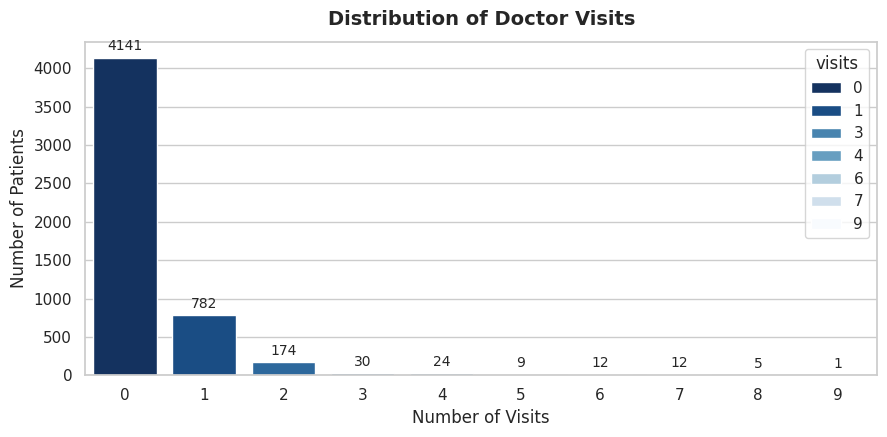

Percentage of individuals with 0 visits: 79.79%


In [8]:
plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=df, x='visits',hue='visits', palette='Blues_r')
plt.title("Distribution of Doctor Visits", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Number of Visits", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)

# Annotate counts on top of bars
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

# Proportion of non-visitors vs visitors
no_visits_pct = (df['visits'] == 0).mean() * 100
print(f"Percentage of individuals with 0 visits: {no_visits_pct:.2f}%")

### 🩺 Step 3: Health Acuity vs. Doctor Consultations
Investigating how reported illnesses and reduced activity days correlate with doctor visits.

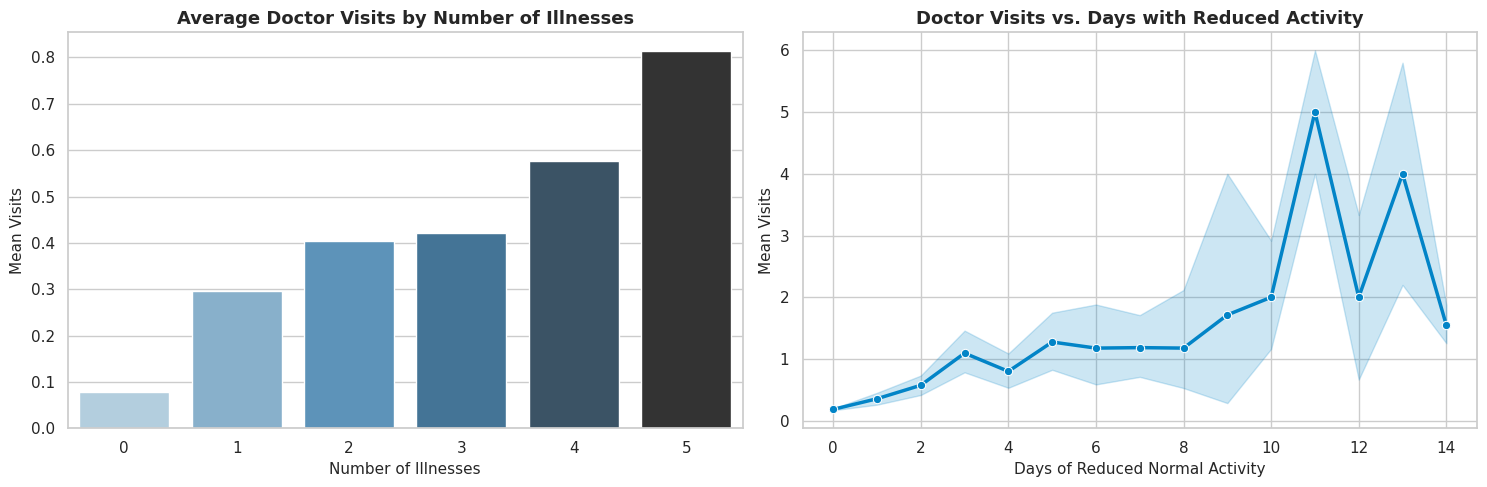

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Visits by Number of Illnesses
sns.barplot(ax=axes[0], data=df, x='illness', y='visits',hue='illness', errorbar=None, palette='Blues_d',legend=False)
axes[0].set_title("Average Doctor Visits by Number of Illnesses", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Illnesses", fontsize=11)
axes[0].set_ylabel("Mean Visits", fontsize=11)

# Visits by Reduced Activity Days
sns.lineplot(ax=axes[1], data=df, x='reduced', y='visits', marker='o', color='#0284c7', linewidth=2.5)
axes[1].set_title("Doctor Visits vs. Days with Reduced Activity", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Days of Reduced Normal Activity", fontsize=11)
axes[1].set_ylabel("Mean Visits", fontsize=11)

plt.tight_layout()
plt.show()

### 👥 Step 4: Demographics and Financial Status
Examining whether gender, age brackets, and household income affect doctor visitation rates.

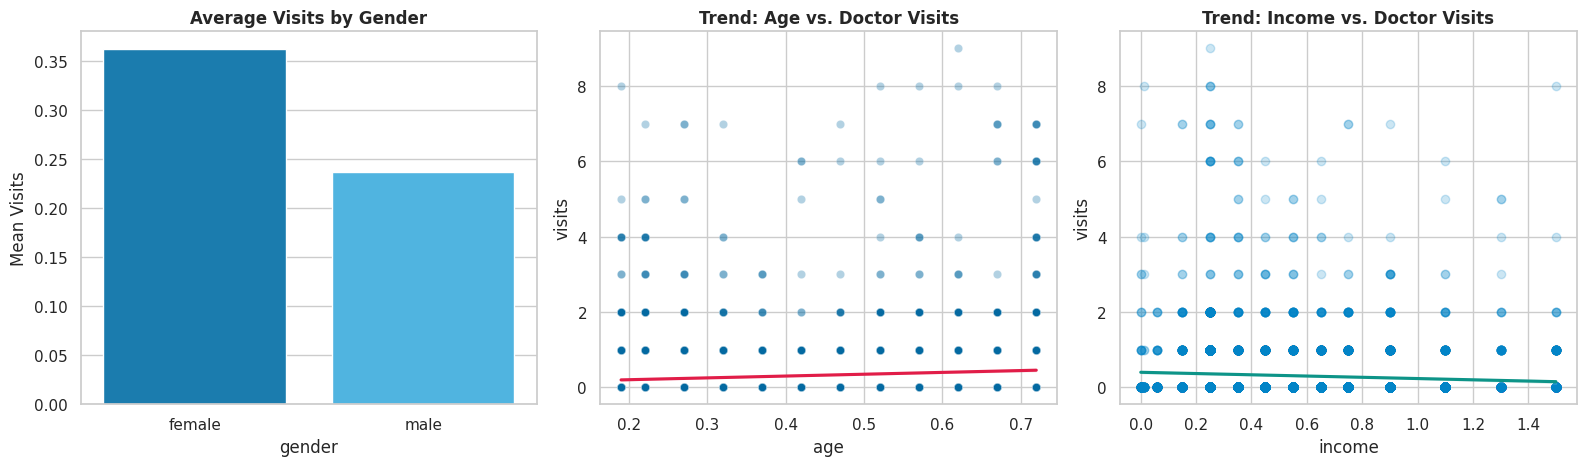

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Gender comparison
sns.barplot(
    ax=axes[0],
    data=df,
    x='gender',
    y='visits',
    hue='gender',
    palette=['#0284c7', '#38bdf8'],
    errorbar=None,
    legend=False
)
axes[0].set_title("Average Visits by Gender", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Mean Visits")

# 2. Age vs Visits
sns.scatterplot(ax=axes[1], data=df, x='age', y='visits', alpha=0.3, color='#0369a1')
sns.regplot(ax=axes[1], data=df, x='age', y='visits', scatter=False, color='#e11d48')
axes[1].set_title("Trend: Age vs. Doctor Visits", fontsize=12, fontweight='bold')

# 3. Income vs Visits
sns.regplot(
    ax=axes[2],
    data=df,
    x='income',
    y='visits',
    scatter_kws={'alpha': 0.2, 'color': '#0284c7'},
    line_kws={'color': '#0d9488'}
)
axes[2].set_title("Trend: Income vs. Doctor Visits", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 🛡️ Step 5: Insurance Support and Vulnerable Groups
Assess the influence of private insurance, government poverty assistance (`freepoor`), and repatriation health coverage (`freerepat`).

Healthcare Access Program Comparison:


,Program,With Program (Mean Visits),Without Program (Mean Visits)
0,Private Insurance,0.294604,0.307400
1,Free Poor Support,0.157658,0.308172
2,Free Repatriation,0.466544,0.257868


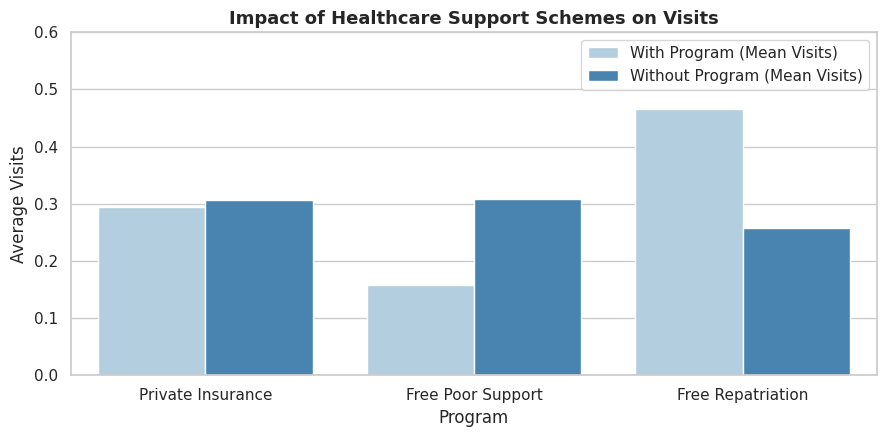

In [9]:
insurance_metrics = pd.DataFrame({
    'Program': ['Private Insurance', 'Free Poor Support', 'Free Repatriation'],
    'With Program (Mean Visits)': [
        df[df['private'] == 'yes']['visits'].mean(),
        df[df['freepoor'] == 'yes']['visits'].mean(),
        df[df['freerepat'] == 'yes']['visits'].mean()
    ],
    'Without Program (Mean Visits)': [
        df[df['private'] == 'no']['visits'].mean(),
        df[df['freepoor'] == 'no']['visits'].mean(),
        df[df['freerepat'] == 'no']['visits'].mean()
    ]
})

print("Healthcare Access Program Comparison:")
display(insurance_metrics)

# Melt for visual comparison
melted_ins = pd.melt(insurance_metrics, id_vars=['Program'], var_name='Status', value_name='Mean_Visits')

plt.figure(figsize=(9, 4.5))
sns.barplot(data=melted_ins, x='Program', y='Mean_Visits', hue='Status', palette='Blues')
plt.title("Impact of Healthcare Support Schemes on Visits", fontsize=13, fontweight='bold')
plt.ylabel("Average Visits")
plt.ylim(0, 0.6)
plt.legend(title="")
plt.tight_layout()
plt.show()

### 📈 Step 6: Feature Correlation & Summary Takeaways
Examining feature correlations and synthesize core analytical conclusions.

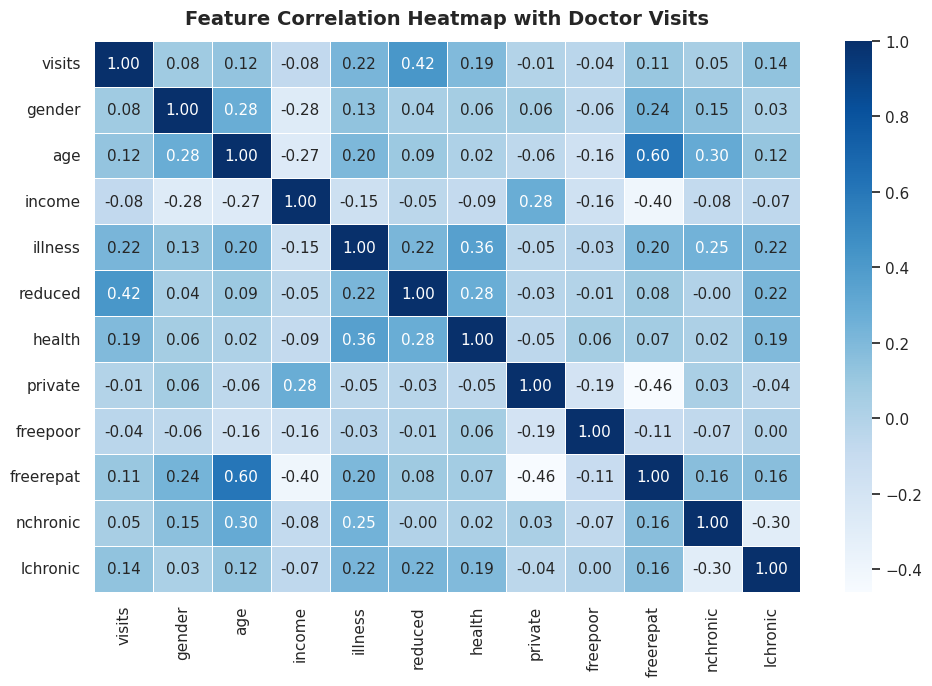

=== KEY ANALYTICAL TAKEAWAYS ===
1. Health Need Driver: 'illness' and 'reduced activity days' have the strongest correlation with visits.
2. Safety Net Utilization: Patients covered under government subsidy ('freepoor' & 'freerepat') visit at higher rates than non-covered patients.
3. Gender Demographics: Females demonstrate higher average visit rates compared to males.


In [10]:
# Convert categorical features to binary numerical values for correlation
df_corr = df.copy()
for col in ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']:
    if col in df_corr.columns:
        df_corr[col] = df_corr[col].map({'yes': 1, 'no': 0, 'female': 1, 'male': 0})

plt.figure(figsize=(10, 7))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="Blues", cbar=True, linewidths=0.5)
plt.title("Feature Correlation Heatmap with Doctor Visits", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Key analytical conclusions
print("=== KEY ANALYTICAL TAKEAWAYS ===")
print("1. Health Need Driver: 'illness' and 'reduced activity days' have the strongest correlation with visits.")
print("2. Safety Net Utilization: Patients covered under government subsidy ('freepoor' & 'freerepat') visit at higher rates than non-covered patients.")
print("3. Gender Demographics: Females demonstrate higher average visit rates compared to males.")